In [1]:
# # Session 10.3 — Distribution Plots: Histplot & Kdeplot
# # આજે આપણે Seaborn માં Data Distribution શીખીશું. Data Science માં માત્ર average જાણવું પૂરતું નથી; ડેટાની values ક્યાં વધુ છે, values કેટલી ફેલાયેલી છે અને distribution નો આકાર કેવો છે તે જાણવું પણ જરૂરી છે.


# 1. Learning objectives
# આ session ના અંતે તમે:
# - Histogram અને KDE વચ્ચેનો તફાવત સમજાવી શકશો.
# - bins, stat, kde=True, fill parameters વાપરી શકશો.
# - એક જ chart માં Histogram અને KDE બનાવી શકશો.
# - Student marks અને business sales ના distribution નું interpretation કરી શકશો.
# - વિદ્યાર્થીઓને આ concepts practical સાથે શીખવી શકશો.
# 2. Distribution એટલે શું?
# ધારો કે 10 વિદ્યાર્થીઓના Python marks આ પ્રમાણે છે:

# 65, 70, 78, 82, 85, 86, 88, 90, 92, 95

# આ values જોઈને આપણે જાણીએ છીએ કે marks 65 થી 95 વચ્ચે છે. પરંતુ કઈ range માં કેટલા વિદ્યાર્થીઓ છે તે વધુ સરળતાથી સમજવા માટે Histogram વાપરીએ છીએ.

# ઉદાહરણ તરીકે, marks ને આ ranges માં વહેંચી શકાય:
# Marks range	વિદ્યાર્થીઓની સંખ્યા
# 60–69	1
# 70–79	2
# 80–89	4
# 90–99	3

# આવી ranges ને bins કહેવામાં આવે છે. Histogram દરેક bin માં આવતી observations ની સંખ્યા બતાવી શકે છે.


In [ ]:
# 3. VS Code માં Practical Setup
# જો તમે Jupyter Notebook વાપરો છો, તો નવી cell માં નીચેનો code copy-paste કરીને ચલાવો.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data = {
    "Student": [
        "Amit", "Neha", "Ravi", "Pooja", "Karan",
        "Meera", "Jay", "Priya", "Rahul", "Nisha"
    ],
    "Department": [
        "IT", "IT", "Computer", "Computer", "IT",
        "Computer", "IT", "Computer", "IT", "Computer"
    ],
    "Python": [85, 92, 70, 88, 65, 95, 78, 82, 90, 86],
    "SQL": [78, 88, 75, 90, 68, 92, 80, 85, 84, 89]
}

df = pd.DataFrame(data)

print(df)

# - pandas DataFrame બનાવે છે.
# - matplotlib.pyplot chart બતાવે છે.
# - seaborn statistical charts બનાવે છે.
# - set_theme() chart ની default styling સેટ કરે છે.
# આગળના બધા student examples માટે આપણે આ જ df વાપરીશું.


  Student Department  Python  SQL
0    Amit         IT      85   78
1    Neha         IT      92   88
2    Ravi   Computer      70   75
3   Pooja   Computer      88   90
4   Karan         IT      65   68
5   Meera   Computer      95   92
6     Jay         IT      78   80
7   Priya   Computer      82   85
8   Rahul         IT      90   84
9   Nisha   Computer      86   89


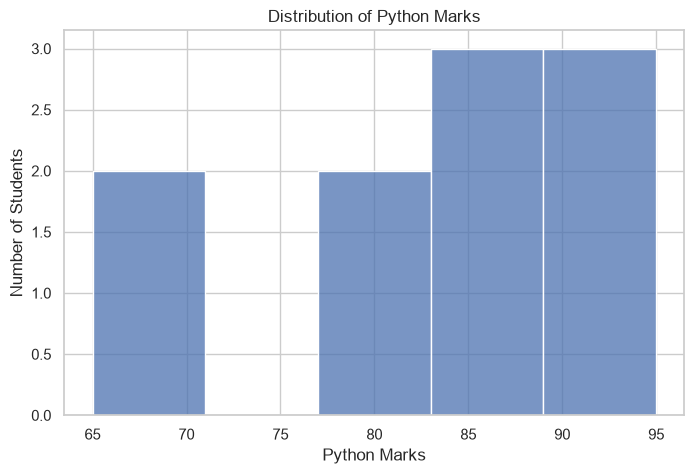

In [ ]:
# 4. Practical 1 — Basic Histogram
# સૌથી પહેલાં Python marks નો Histogram બનાવીએ

plt.figure(figsize=(8,5)) # chart ni size

sns.histplot(
    data=df,
    x="Python",
    bins=5 # Marks ની range ને 5 intervals માં વહેંચે છે
)


plt.title("Distribution of Python Marks")
plt.xlabel("Python Marks")
plt.ylabel("Number of Students")

plt.show()

# ઓછા bins: મોટું picture સરળતાથી દેખાય, પરંતુ detail ગુમાઈ શકે.
# વધુ bins: વધુ detail દેખાય, પરંતુ chart અનિયમિત અથવા noisy લાગી શકે.
# કોઈ એક bins value દરેક dataset માટે શ્રેષ્ઠ નથી.

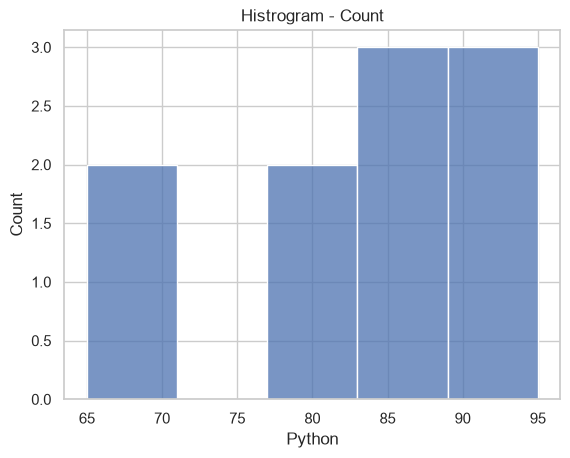

In [ ]:
# # 5. bins parameter ઊંડાણથી સમજો
# # bins Histogram નો દેખાવ અને detail બદલે છે.

# 6. Practical 2 — stat parameter
# Histogram નો Y-axis ફક્ત count જ દર્શાવે એવું જરૂરી નથી. stat દ્વારા આપણે અન્ય પ્રકારની માહિતી પણ બતાવી શકીએ છીએ.

# A. Count — observations ની સંખ્યા

sns.histplot(
    data=df,
    x="Python",
    bins=5,
    stat="count" # count defult behiviore che
)

plt.title("Histrogram - Count")
plt.show()

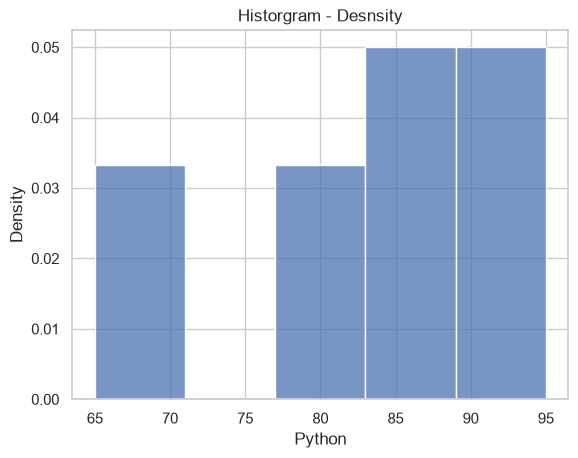

In [ ]:
# B. Density — normalized distribution

sns.histplot(
    data=df,
    x="Python",
    bins=5,
    stat="density"
)

plt.title("Historgram - Desnsity")
plt.show()

# stat="density" વાપરવાથી Y-axis density દર્શાવે છે. આ સ્થિતિમાં Histogram ના bars હેઠળનું કુલ area 1 થાય છે.

# આથી count અને density અલગ રીતે સમજવા:
# stat	Y-axis શું બતાવે છે?
# "count"	દરેક bin માં observations ની સંખ્યા
# "frequency"	દરેક bin ની count ને bin width વડે ભાગ્યા પછીની value
# "probability"	દરેક bin માં observations નો પ્રમાણ
# "percent"	દરેક bin માં observations ની ટકાવારી
# "density"	normalized density; કુલ bar area 1

# frequency અને density એક જ નથી: frequency bin width પ્રમાણે count ને scale કરે છે, જ્યારે density ને કુલ area 1 મળે છે.


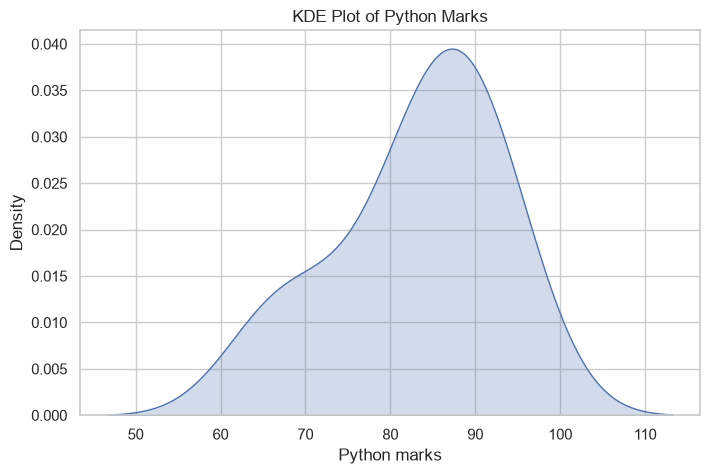

In [9]:
# 7. Practical 3 — KDE Plot શું છે?
# KDE નું full form Kernel Density Estimation છે. તે observations ના distribution નો smooth અંદાજ બનાવે છે.

# Histogram માં bars હોય છે, જ્યારે KDE માં smooth curve હોય છે.

plt.figure(figsize=(8,5))

sns.kdeplot(
    data=df,
    x="Python",
    fill=True # KDE curve color bhari dese
    # fill=False # only cuve
)

plt.title("KDE Plot of Python Marks")
plt.xlabel("Python marks")
plt.ylabel("Density")

plt.show()

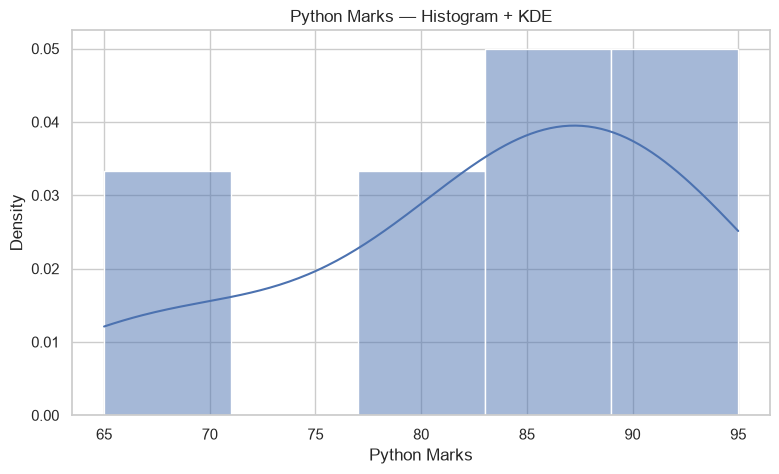

In [ ]:
# 8. Practical 4 — Histogram અને KDE એક જ Chart માં
# હવે બંનેને combine કરીએ. આ session નો સૌથી મહત્વપૂર્ણ practical છે.

plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="Python",
    bins=5,
    stat="density", # historgaming
    kde=True # curv add karse
)
plt.title("Python Marks — Histogram + KDE")
plt.xlabel("Python Marks")
plt.ylabel("Density")

plt.show()

# historgam : bins and bervations 
# KDE : Distrubiutuib 
# historram + KDE


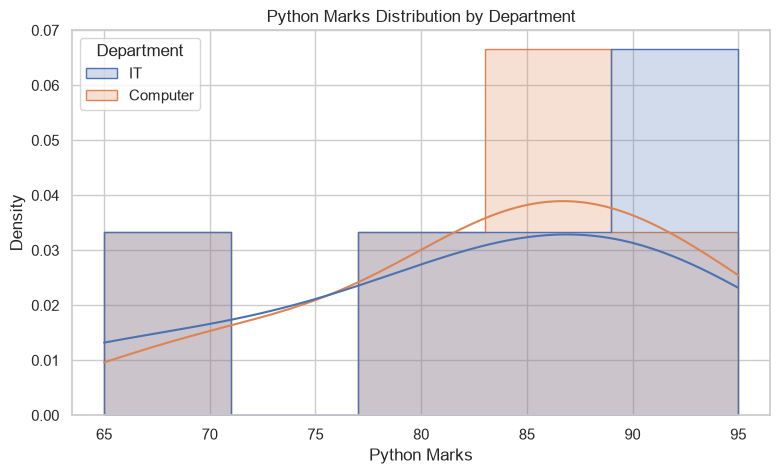

In [13]:
# 9. Practical 5 — fill અને hue
# હવે IT અને Computer department ના Python marks અલગ-अलग જોીએ.

plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="Python",
    hue="Department",
    bins=5,
    stat="density",
    common_norm=False,
    element="step",
    kde=True
)

plt.title("Python Marks Distribution by Department")
plt.xlabel("Python Marks")
plt.ylabel("Density")

plt.show()

In [14]:
# Parameter	શું કરે છે?
# hue="Department"	Department પ્રમાણે અલગ distributions દર્શાવે છે.
# common_norm=False	દરેક group ની density અલગથી normalize કરે છે.
# element="step"	Histogram ને outline/step સ્વરૂપે દર્શાવે છે, જેથી overlap સમજવો સરળ બને.
# kde=True	દરેક group માટે KDE curve ઉમેરે છે.

# hue દ્વારા આપણે જોઈ શકીએ કે IT અને Computer ના marks કઈ ranges માં વધુ એકત્રિત છે.

# જો બંને distributions overlap થાય, તો બંને groups ની marks ranges માં સમાનતા હોઈ શકે. પરંતુ નાનાં samples માંથી મજબૂત નિષ્કર્ષ ન કાઢવો.



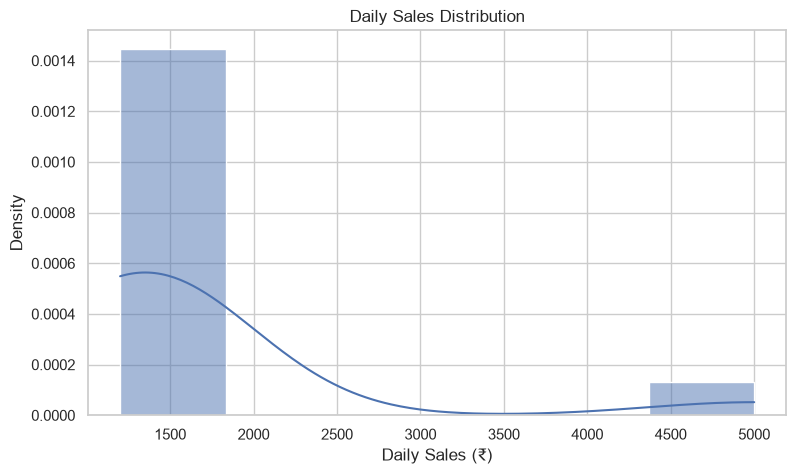

In [ ]:
# 10. Practical 6 — Business Sales Distribution
# હવે વિદ્યાર્થીના marks ને બદલે business data પર આ જ concepts વાપરીએ.

sales_df = pd.DataFrame({
    "Day": list(range(1, 13)),
    "Sales": [
        1200, 1350, 1280, 1400,
        1320, 1250, 1380, 1300,
        1450, 1500, 1420, 5000
    ]
})

plt.figure(figsize=(9, 5))

sns.histplot(
    data=sales_df,
    x="Sales",
    bins=6,
    stat="density",
    kde=True
)

plt.title("Daily Sales Distribution")
plt.xlabel("Daily Sales (₹)")
plt.ylabel("Density")

plt.show()


# 1. બધા મહત્વપૂર્ણ parameters — Quick Revision
# Parameter	Example	ઉપયોગ
# bins	bins=10	Histogram intervals ની સંખ્યા
# stat	stat="density"	Y-axis પર કયો statistical measure દર્શાવવો
# kde	kde=True	Histogram પર KDE curve ઉમેરવો
# fill	fill=True	KDE curve નીચેનો વિસ્તાર ભરવો
# hue	hue="Department"	Category પ્રમાણે distributions અલગ દર્શાવવાં
# common_norm	common_norm=False	Groups ની density normalization નિયંત્રિત કરવી
# element	element="step"	Histogram bars નું rendering style
# bw_adjust	bw_adjust=0.7	KDE ની smoothness બદલવી


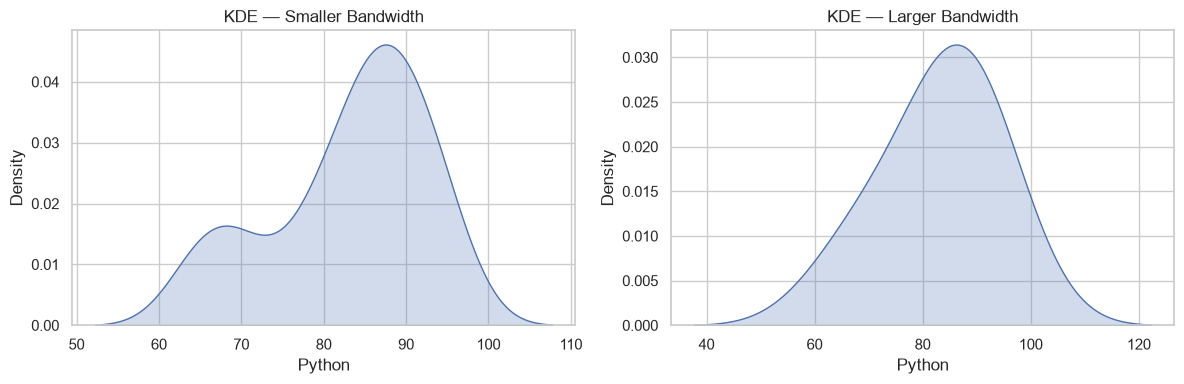

In [ ]:
# KDE માં bw_adjust નો ઉપયોગ

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(
    data=df,
    x="Python",
    fill=True,
    bw_adjust=0.7, #curve વધુ વિગતવાર અને વધુ વળાંકવાળો થઈ શકે છે.
    ax=ax[0]
)
ax[0].set_title("KDE — Smaller Bandwidth")

sns.kdeplot(
    data=df,
    x="Python",
    fill=True,
    bw_adjust=1.5, # curve વધુ smooth થઈ શકે છે.
    ax=ax[1]
)
ax[1].set_title("KDE — Larger Bandwidth")

plt.tight_layout()
plt.show()